# Lab 2 · Un agente con LangGraph: el agente como grafo

> **[ANCLA · M1]** Este lab es uno de los pilares de M1 (LangGraph desde cero). Hazlo entero.

**KEEPCODING · AI Engineering · Clase 5 · Módulo M1 "Agentes con LangChain"**

En el Lab 1 usamos un agente ReAct *prebuilt*: una caja negra que ya traía el bucle "piensa, actúa, observa" montado. En este Lab 2 abrimos esa caja. Vamos a construir el mismo tipo de agente, pero **a mano**, como un grafo explícito de nodos y aristas usando **LangGraph**.

## Qué necesitas

- Una clave de API de OpenAI en la variable de entorno `OPENAI_API_KEY`.
- Este notebook corre tal cual en **Google Colab** o en un **Jupyter** local. Solo necesitas conexión a internet para instalar paquetes y para llamar al LLM (y, opcionalmente, a la API de One Piece).

> Si no defines `OPENAI_API_KEY`, las celdas que llaman al LLM fallarán. El resto del código (tools, definición del grafo) funciona igual.

## Para quién es

Para alumnado que ya completó el Lab 1 (agente ReAct prebuilt) y quiere entender qué hay **por debajo**: estado, nodos, aristas y memoria.

## Qué vas a poder hacer al terminar

1. Definir el `State` de un grafo con `TypedDict` y `add_messages`.
2. Escribir los nodos `agent` (el LLM) y `tools` (la ejecución de herramientas).
3. Conectar nodos con aristas normales y con una **arista condicional**.
4. Compilar el grafo y **visualizarlo** como diagrama.
5. Ejecutarlo con `stream` y ver la ejecución nodo a nodo.
6. Añadir **memoria** con checkpointing y `thread_id`.

## El hilo conductor: la API de One Piece

Como en el Lab 1, el agente trabaja con datos del mundo de One Piece. Usaremos una tool `buscar_personaje` que consulta la API pública de [api-onepiece.com](https://api-onepiece.com) y, si falla, cae a datos hardcodeados. Así la clase nunca se rompe por un problema de red.

### Por qué importa

Los frameworks esconden el bucle del agente. Abrir la caja (estado, nodos, aristas) es lo que te deja **depurar, añadir control y persistencia** cuando un prebuilt se queda corto. Es la base del Corrective RAG del Lab 4.

### Conecta con

- **Slides M1** · LangGraph, grafos de agentes.
- **Lab 1** · el ReAct prebuilt (el contraste: caja negra vs grafo explícito).
- **Lab 4** · este mismo grafo, ahora con un nodo que se autoverifica.
- **M5** · el loop del agente sin ningún framework.

### Stack

`langgraph>=1.0` · `langchain-openai` · `gpt-5-mini`.

### Hardware

Cualquier CPU; Colab Free sobra (no usa GPU, todo es API).


## Recorrido del lab

1. **Setup**: instalar paquetes y configurar la API key.
2. **El estado**: definir el `State` del grafo con `TypedDict` y `add_messages`.
3. **Las tools**: una tool sobre la API de One Piece, robusta ante fallos de red.
4. **Los nodos**: el nodo `agent` (llama al LLM) y el nodo `tools` (ejecuta herramientas).
5. **Las aristas**: conectar nodos y añadir una arista condicional que decide el camino.
6. **Compilar y visualizar**: dibujar el grafo dentro del notebook.
7. **Ejecutar con `stream`**: ver la ejecución nodo a nodo.
8. **Memoria**: recompilar con checkpointing y conversar con `thread_id`.
9. **Recap y retos**.

> Idea clave del lab: un agente **es** un grafo. El prebuilt del Lab 1 era este mismo grafo, montado por ti sin que lo vieras.


## 1. Setup

Instalamos dos paquetes:

- `langgraph`: para construir el grafo (estado, nodos, aristas, checkpointing).
- `langchain-openai`: el conector con los modelos de OpenAI.

Para la API de One Piece usamos `urllib`, de la librería estándar de Python.

La instalación es silenciosa (`-q`). Si ya los tienes, no pasa nada: pip los deja como están.


In [1]:
# Instalación de dependencias (silenciosa)
%pip install -q langgraph langchain-openai

### Configurar la API key

Necesitamos `OPENAI_API_KEY` en el entorno. La celda siguiente:

- En **Colab**, intenta leerla desde los *Secrets* (el icono de la llave en la barra lateral).
- Si no la encuentra, te la pide por teclado con `getpass` (no se ve mientras escribes).

Así el notebook funciona igual en Colab y en Jupyter local.


In [2]:
# Configuración de la API key de OpenAI
import os
from getpass import getpass


def cargar_api_key() -> None:
    """Deja OPENAI_API_KEY en el entorno (Colab Secrets, entorno o teclado)."""
    if os.environ.get("OPENAI_API_KEY"):
        print("OPENAI_API_KEY ya está definida en el entorno.")
        return

    # Intento 1: Secrets de Google Colab
    try:
        from google.colab import userdata  # type: ignore

        clave = userdata.get("OPENAI_API_KEY")
        if clave:
            os.environ["OPENAI_API_KEY"] = clave
            print("OPENAI_API_KEY cargada desde los Secrets de Colab.")
            return
    except Exception:
        pass  # No estamos en Colab o el secret no existe

    # Intento 2: pedirla por teclado
    os.environ["OPENAI_API_KEY"] = getpass("Introduce tu OPENAI_API_KEY: ")
    print("OPENAI_API_KEY configurada.")


cargar_api_key()


OPENAI_API_KEY ya está definida en el entorno.


## 2. El estado del grafo

Un grafo de LangGraph necesita un **estado**: la estructura de datos que viaja entre nodos. Cada nodo recibe el estado, hace su trabajo y devuelve una **actualización** del estado.

Para un agente conversacional el estado mínimo es una lista de mensajes. Lo definimos con un `TypedDict`:

```python
class State(TypedDict):
    messages: Annotated[list, add_messages]
```

Lo importante es el `Annotated[list, add_messages]`. Esa anotación le dice a LangGraph **cómo combinar** las actualizaciones:

- Sin `add_messages`, cada nodo *sobrescribiría* la lista de mensajes.
- Con `add_messages`, cada nodo *añade* sus mensajes a la conversación (y sabe deduplicar por id).

`add_messages` es lo que convierte la lista en una conversación que crece. Es la pieza que hace posible el bucle del agente.


In [3]:
# Definición del estado del grafo
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph.message import add_messages


class State(TypedDict):
    """Estado del agente: solo necesita la conversación."""
    messages: Annotated[list, add_messages]
    condition_exit: int


print("State definido. Campo 'messages' con reducer add_messages.")


State definido. Campo 'messages' con reducer add_messages.


### Mini-demo: qué hace `add_messages`

Antes de seguir, veamos el reducer en acción sin grafo de por medio. `add_messages(viejos, nuevos)` toma la lista actual y la actualización, y devuelve la lista combinada.


In [4]:
# Mini-demo del reducer add_messages
from langchain_core.messages import HumanMessage, AIMessage

historial = [AIMessage(content="¡Hola! ¿En qué te ayudo?"),
             HumanMessage(content="Hola, soy un alumno de KeepCoding"),
             AIMessage(content="Encantado de ayudarte")]

nuevo = [HumanMessage(content="Quiero apuntarme al bootcamp de IA")]

combinado = add_messages(historial, nuevo)
for m in combinado:
    print(f"{m.type:>6}: {m.content}")


    ai: ¡Hola! ¿En qué te ayudo?
 human: Hola, soy un alumno de KeepCoding
    ai: Encantado de ayudarte
 human: Quiero apuntarme al bootcamp de IA


## 3. Las tools: la API de One Piece

El agente necesita algo que hacer. Le damos una tool, `buscar_personaje`, que devuelve la **recompensa** (*bounty*) de un personaje de One Piece.

Estrategia de robustez (la misma del Lab 1):

1. Intenta la API en vivo de `api-onepiece.com`.
2. Si la red falla, hay timeout o el personaje no aparece, **cae a un diccionario hardcodeado** con los Sombrero de Paja y sus recompensas post-Wano.

Así la clase funciona igual con o sin internet. Una tool de producción **siempre** debe tener un plan B.


In [5]:
# Datos hardcodeados: recompensas post-Wano (plan B si la API falla)
RECOMPENSAS_SOMBRERO_DE_PAJA = {
    "luffy": {"nombre": "Monkey D. Luffy", "recompensa": 3_000_000_000},
    "zoro": {"nombre": "Roronoa Zoro", "recompensa": 1_111_000_000},
    "nami": {"nombre": "Nami", "recompensa": 366_000_000},
    "usopp": {"nombre": "Usopp", "recompensa": 500_000_000},
    "sanji": {"nombre": "Vinsmoke Sanji", "recompensa": 1_032_000_000},
    "chopper": {"nombre": "Tony Tony Chopper", "recompensa": 1_000},
    "robin": {"nombre": "Nico Robin", "recompensa": 930_000_000},
    "franky": {"nombre": "Franky", "recompensa": 394_000_000},
    "brook": {"nombre": "Brook", "recompensa": 383_000_000},
    "jinbe": {"nombre": "Jinbe", "recompensa": 1_100_000_000},
}

print(f"Datos de respaldo cargados: {len(RECOMPENSAS_SOMBRERO_DE_PAJA)} personajes.")


Datos de respaldo cargados: 10 personajes.


In [6]:
# La tool: buscar_personaje (API en vivo con fallback)
import urllib.request
import json
import unicodedata
from langchain_core.tools import tool

# Cache en memoria: la lista completa de personajes se descarga una sola vez.
_OP_CACHE = []


def _normalizar(texto: str) -> str:
    """Minúsculas, sin acentos ni puntuación, espacios colapsados."""
    t = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    t = "".join(c if c.isalnum() else " " for c in t.lower())
    return " ".join(t.split())


def _coincide(consulta: str, nombre: str) -> bool:
    """True si 'consulta' identifica a 'nombre'. Tolera puntos, acentos y orden.

    El LLM puede pasar "Luffy" o "Monkey D. Luffy"; la API guarda
    "Monkey D Luffy" (sin punto). Normalizamos ambos y comparamos por
    contención o por palabras, nunca con un substring frágil.
    """
    q, n = _normalizar(consulta), _normalizar(nombre)
    if not q or not n:
        return False
    if q == n or q in n or n in q:
        return True
    palabras = [w for w in q.split() if len(w) >= 3]
    return bool(palabras) and all(w in n.split() for w in palabras)


def _cargar_personajes_op():
    """Descarga (una sola vez) la lista completa de personajes de One Piece."""
    global _OP_CACHE
    if _OP_CACHE:
        return _OP_CACHE
    url = "https://api.api-onepiece.com/v2/characters/en"
    req = urllib.request.Request(url, headers={"User-Agent": "keepcoding-ai-lab/1.0"})
    with urllib.request.urlopen(req, timeout=25) as r:
        _OP_CACHE = json.load(r)
    return _OP_CACHE


@tool
def buscar_personaje(nombre: str) -> str:
    """Busca un personaje de One Piece y devuelve su recompensa (bounty) en berries.

    Args:
        nombre: nombre del personaje a buscar, por ejemplo "Luffy" o "Zoro".
    """
    # Intento 1: API en vivo (lista completa cacheada, se filtra en Python).
    try:
        for c in _cargar_personajes_op():
            if _coincide(nombre, c.get("name") or ""):
                bounty = c.get("bounty") or "desconocida"
                return f"{c['name']} tiene una recompensa de {bounty} berries (fuente: API en vivo)."
        return f"No se encontró a '{nombre}' en la API de One Piece."
    except Exception as error:
        print(f"  [tool] API no disponible ({type(error).__name__}), uso datos locales.")

    # Intento 2: datos hardcodeados
    for posible, info in RECOMPENSAS_SOMBRERO_DE_PAJA.items():
        if _coincide(nombre, posible) or _coincide(nombre, info["nombre"]):
            recompensa = f"{info['recompensa']:,}".replace(",", ".")
            return f"{info['nombre']} tiene una recompensa de {recompensa} berries (fuente: datos locales)."

    return (
        f"No encontré a '{nombre}'. Personajes disponibles en los datos locales: "
        + ", ".join(info["nombre"] for info in RECOMPENSAS_SOMBRERO_DE_PAJA.values())
        + "."
    )


# Lista de tools que el agente podrá usar
tools = [buscar_personaje]
print("Tool registrada:", buscar_personaje.name)

Tool registrada: buscar_personaje


### Probar la tool por separado

Antes de meterla en el grafo, comprobamos que la tool funciona sola. Una tool se invoca con `.invoke()` pasando un diccionario con sus argumentos.


In [7]:
# Prueba directa de la tool
print(buscar_personaje.invoke({"nombre": "Zoro"}))
print(buscar_personaje.invoke({"nombre": "Nami"}))
print(buscar_personaje.invoke({"nombre": "Kaido"}))


Roronoa Zoro tiene una recompensa de 1.101.000.000 berries (fuente: API en vivo).
Nami tiene una recompensa de 366.000.000 berries (fuente: API en vivo).
Kaido tiene una recompensa de 4.611.100.000 berries (fuente: API en vivo).


## 4. Los nodos del grafo

Un **nodo** es una función: recibe el estado y devuelve una actualización del estado. Nuestro agente tiene dos nodos.

### Nodo `agent`

Llama al LLM. Antes le **bindeamos** las tools con `llm.bind_tools(tools)`: así el modelo sabe qué herramientas existen y puede decidir llamarlas. El nodo recibe los mensajes, invoca al modelo y devuelve la respuesta del LLM como un mensaje nuevo.

### Nodo `tools`

Cuando el LLM pide usar una tool, su respuesta incluye `tool_calls`. Alguien tiene que ejecutarlas de verdad. Eso lo hace `ToolNode`, un nodo que LangGraph ya nos da hecho: lee los `tool_calls` del último mensaje, ejecuta cada tool y devuelve los resultados como `ToolMessage`.

Empezamos creando el LLM con las tools bindeadas.


In [8]:
# El LLM con las tools bindeadas
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-5-mini", temperature=0)

# bind_tools: el modelo ahora "conoce" buscar_personaje y puede pedir usarla
llm_con_tools = llm.bind_tools(tools)

print("LLM listo con", len(tools), "tool(s) bindeada(s).")


LLM listo con 1 tool(s) bindeada(s).


In [9]:
# Nodo 'agent': llama al LLM con el historial de mensajes
def agent(state: State) -> dict:
    """Invoca al LLM y devuelve su respuesta como actualización del estado."""
    respuesta = llm_con_tools.invoke(state["messages"])
    # Devolvemos solo lo nuevo: add_messages lo añadirá a la conversación
    return {"messages": [respuesta]}


print("Nodo 'agent' definido.")


Nodo 'agent' definido.


In [10]:
# Nodo 'tools': ToolNode ejecuta las tools que pida el LLM
from langgraph.prebuilt import ToolNode

tool_node = ToolNode(tools)

print("Nodo 'tools' creado con ToolNode.")


Nodo 'tools' creado con ToolNode.


## 5. Las aristas: el cableado del grafo

Los nodos no hacen nada sueltos. Las **aristas** (*edges*) deciden el flujo. Hay dos tipos.

### Aristas normales

Van siempre de un nodo a otro:

- `START -> agent`: toda ejecución empieza llamando al LLM.
- `tools -> agent`: después de ejecutar tools, volvemos al LLM para que interprete el resultado.

### Arista condicional

Aquí está la inteligencia del bucle. Después del nodo `agent` hay que **decidir**:

- Si el LLM pidió usar una tool (su mensaje tiene `tool_calls`), vamos a `tools`.
- Si el LLM dio una respuesta final (sin `tool_calls`), vamos a `END` y terminamos.

Esa decisión la toma una función `route(state)` que mira el último mensaje. Esto es **exactamente** el bucle ReAct del Lab 1, pero ahora lo escribimos nosotros.


In [11]:
# La función de enrutado: decide a dónde ir después del nodo agent
from langgraph.graph import END


def route(state: State) -> str:
    """Mira el último mensaje y decide el siguiente paso.

    Devuelve "tools" si el LLM pidió una herramienta, o END si ya respondió.
    """

    ultimo_mensaje = state["messages"][-1]
    if getattr(ultimo_mensaje, "tool_calls", None):
        print("******")
        print(ultimo_mensaje.tool_calls)
        print("******")
        return "tools"
    return END


print("Función route() definida.")


Función route() definida.


### Montar el grafo

Ya tenemos las piezas. Construimos el `StateGraph` parametrizado con nuestro `State`, registramos los dos nodos y conectamos las aristas:

1. `add_node(...)` para `agent` y `tools`.
2. `add_edge(START, "agent")`: el punto de entrada.
3. `add_conditional_edges("agent", route, path_map)`: la bifurcación. El `path_map` declara explícitamente los destinos posibles (`"tools"` y `END`), para que la topología del grafo los incluya y el dibujo los muestre. Sin `path_map`, el visualizador no sabría que `tools` es un destino de la condicional y el nodo aparecería suelto.
4. `add_edge("tools", "agent")`: el regreso al LLM tras usar tools.

In [12]:
# Construcción del grafo
from langgraph.graph import StateGraph, START, END

builder = StateGraph(State)

# 1. Registrar los nodos
builder.add_node("agent", agent)
builder.add_node("tools", tool_node)

# 2. Aristas
builder.add_edge(START, "agent")  # entrada: siempre empezamos en el LLM

# Bifurcación: el path_map mapea cada valor que devuelve route() al nodo destino.
# Lo necesitamos explícito para que el grafo registre las aristas 'agent -> tools'
# y 'agent -> END' (si no, la visualización deja 'tools' colgando suelto).
builder.add_conditional_edges(
    "agent",
    route,
    {"tools": "tools", END: END},
)

builder.add_edge("tools", "agent")  # tras usar tools, volvemos al LLM

print("Grafo construido. Nodos: agent, tools.")

Grafo construido. Nodos: agent, tools.


## 6. Compilar y visualizar el grafo

`builder` es solo el plano. Hay que **compilarlo** con `builder.compile()` para obtener un grafo ejecutable.

Lo bueno de tener el grafo explícito: lo podemos **dibujar**. `graph.get_graph().draw_mermaid_png()` genera un PNG del diagrama, y lo mostramos dentro del notebook con `IPython.display.Image`.


In [13]:
# Compilar el grafo
graph = builder.compile()
print("Grafo compilado y listo para ejecutar.")


Grafo compilado y listo para ejecutar.


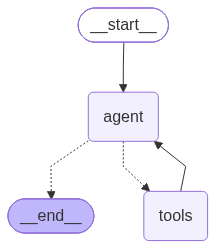

In [14]:
# Visualizar el grafo como diagrama
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as error:
    # draw_mermaid_png necesita red (usa un servicio externo). Plan B: texto.
    print(f"No se pudo renderizar el PNG ({type(error).__name__}). Diagrama en texto:")
    print(graph.get_graph().draw_ascii())


### Leer el diagrama

En el diagrama verás el flujo completo:

- `__start__` entra siempre a `agent`.
- Desde `agent` salen **dos** flechas (la arista condicional): una a `tools`, otra a `__end__`.
- `tools` vuelve siempre a `agent`.

Ese ciclo `agent -> tools -> agent` es el **bucle del agente**. El LLM piensa, ejecuta una tool, ve el resultado y vuelve a pensar, hasta que decide que ya puede responder y sale por `__end__`.


## 7. Ejecutar el grafo con `stream`

Para ejecutar el grafo podríamos usar `graph.invoke(...)` y obtener solo el resultado final. Pero para **aprender** es más útil `graph.stream(...)`: nos va entregando el estado **nodo a nodo**, según se ejecutan.

Le pasamos como entrada un diccionario con el estado inicial: la pregunta del usuario en `messages`. Cada paso del stream es un diccionario `{nombre_del_nodo: actualizacion}`.


In [15]:
entrada = {"messages": "¿Quién es Leo Messi?"}

graph.invoke(entrada)

{'messages': [HumanMessage(content='¿Quién es Leo Messi?', additional_kwargs={}, response_metadata={}, id='70782a42-1200-4dff-be03-b3541770d18d'),
  AIMessage(content='Lionel Andrés “Leo” Messi (nacido el 24 de junio de 1987 en Rosario, Argentina) es un futbolista argentino considerado uno de los mejores jugadores de la historia.\n\nPuntos clave:\n- Posición: delantero / mediapunta, conocido por su dribbling, visión de juego y definición.\n- Trayectoria: surgió en las categorías juveniles de Newell’s Old Boys; se incorporó a La Masia (FC Barcelona) siendo adolescente y debutó con el primer equipo en 2004. Tras una carrera histórica en el Barcelona, jugó en el Paris Saint‑Germain (PSG) y, desde 2023, en Inter Miami en la MLS.\n- Selección: capitán de la selección argentina; ganó la Copa América 2021 y la Copa Mundial de la FIFA 2022 con Argentina.\n- Palmarés individual: ha ganado múltiples Balones de Oro (récord con 8 hasta 2023) y numerosos premios individuales por su rendimiento.\n- 

In [16]:
# Ejecutar el grafo viendo cada nodo
pregunta = "¿Cuál es la recompensa de Zoro? ¿Y la de Nami?"

entrada = {"messages": [HumanMessage(content=pregunta)]}

for paso in graph.stream(entrada, stream_mode="updates"):
    for nombre_nodo, actualizacion in paso.items():
        print(f"=== Nodo ejecutado: {nombre_nodo} ===")
        for mensaje in actualizacion["messages"]:
            mensaje.pretty_print()
        print()


******
[{'name': 'buscar_personaje', 'args': {'nombre': 'Zoro'}, 'id': 'call_aKCh3dqbbcwCeRLC95cXTSek', 'type': 'tool_call'}, {'name': 'buscar_personaje', 'args': {'nombre': 'Nami'}, 'id': 'call_Zkq2vEHhtnUCcwsphADTiurh', 'type': 'tool_call'}]
******
=== Nodo ejecutado: agent ===
================================== Ai Message ==================================
Tool Calls:
  buscar_personaje (call_aKCh3dqbbcwCeRLC95cXTSek)
 Call ID: call_aKCh3dqbbcwCeRLC95cXTSek
  Args:
    nombre: Zoro
  buscar_personaje (call_Zkq2vEHhtnUCcwsphADTiurh)
 Call ID: call_Zkq2vEHhtnUCcwsphADTiurh
  Args:
    nombre: Nami

=== Nodo ejecutado: tools ===
================================= Tool Message =================================
Name: buscar_personaje

Roronoa Zoro tiene una recompensa de 1.101.000.000 berries (fuente: API en vivo).
================================= Tool Message =================================
Name: buscar_personaje

Nami tiene una recompensa de 366.000.000 berries (fuente: API en vivo).

=== Nodo ejecutado: agent ===
================================== Ai Message ==================================

- Roronoa Zoro: 1.101.000.000 berries.  
- Nami: 366.000.000 berries.

Fuente: API en vivo. Estas cifras pueden cambiar si se anuncian nuevas actualizaciones, ¿quieres que busque la recompensa de algún otro personaje?



### Qué acabas de ver

Sigue la traza de arriba y verás el bucle completo:

1. **Nodo `agent`**: el LLM no responde directamente. Emite un mensaje con `tool_calls` (quiere buscar a Zoro y a Nami).
2. **Nodo `tools`**: `ToolNode` ejecuta `buscar_personaje` para cada llamada y devuelve los resultados como `ToolMessage`.
3. **Nodo `agent` otra vez**: el LLM ya tiene los datos y redacta la respuesta final, sin más `tool_calls`.
4. La arista condicional `route` devuelve `END` y el grafo termina.

Nadie escondió nada: cada paso del razonamiento del agente es un nodo que se ejecutó y lo viste.


## 8. Memoria: checkpointing y `thread_id`

El grafo que ejecutamos **no recuerda nada**. Cada llamada a `stream` empieza de cero: si ahora preguntamos "¿y cuál era el primero?", el agente no tiene ni idea.

LangGraph resuelve esto con **checkpointing**. Al compilar el grafo le pasamos un *checkpointer*: tras cada nodo, guarda el estado completo. Para empezar usamos `MemorySaver`, que guarda en memoria RAM (perfecto para clase; en producción usarías uno con base de datos).

Con checkpointing, cada conversación se identifica con un `thread_id`. Mientras uses el mismo `thread_id`, el grafo **continúa** esa conversación en vez de empezar otra.


In [17]:
# Recompilar el MISMO grafo, ahora con memoria
from langgraph.checkpoint.memory import MemorySaver

memoria = MemorySaver()
graph_con_memoria = builder.compile(checkpointer=memoria)

print("Grafo recompilado con checkpointer MemorySaver.")


Grafo recompilado con checkpointer MemorySaver.


### Una función para conversar

Para los turnos de la conversación creamos un pequeño ayudante. Lo importante es el `config`: el diccionario `{"configurable": {"thread_id": ...}}` le dice al grafo **en que conversación** estamos.


In [18]:
# Ayudante para enviar un turno al agente con memoria
def conversar(texto: str, thread_id: str) -> None:
    """Envía un mensaje al agente dentro de la conversación thread_id."""
    config = {"configurable": {"thread_id": thread_id}}
    entrada = {"messages": [HumanMessage(content=texto)]}

    resultado = graph_con_memoria.invoke(entrada, config=config)
    respuesta_final = resultado["messages"][-1]

    print(f"Usuario: {texto}")
    print(f"Agente : {respuesta_final.content}")
    print("-" * 60)


print("Función conversar() lista.")


Función conversar() lista.


### Turno 1: el alumno dice su personaje favorito

Abrimos la conversación `clase-keepcoding`. En este primer turno el usuario comparte un dato personal: su personaje favorito.


In [19]:
# Turno 1: el usuario comparte su personaje favorito
HILO = "clase-keepcoding"

conversar("¡Hola! Mi personaje favorito de One Piece es Jinbe.", thread_id=HILO)


******
[{'name': 'buscar_personaje', 'args': {'nombre': 'Jinbe'}, 'id': 'call_dasbcy4HJFa5wxYHKExdx4wD', 'type': 'tool_call'}]
******


Usuario: ¡Hola! Mi personaje favorito de One Piece es Jinbe.
Agente : ¡Qué buen gusto! Jinbe es un gran personaje.

Recompensa: 1.100.000.000 berries.

Datos breves:
- Es un hombre-pez (especie: tiburón ballena).
- Maestro del karate de hombre-pez y luchador muy fuerte.
- Fue capitán de los Sun Pirates y miembro ex-Shichibukai.
- Actualmente es timonel (helmsman) de los Sombrero de Paja y miembro oficial de la tripulación.
¿Quieres que te cuente sus mejores momentos/peleas, su historia completa o alguna curiosidad sobre él?
------------------------------------------------------------


### Turno 2: una pregunta intermedia

Segundo turno, mismo `thread_id`. El usuario pregunta algo que obliga al agente a usar la tool. La conversación sigue acumulándose en el estado del hilo.


In [20]:
# Turno 2: una consulta que usa la tool
conversar("¿Cuál es la recompensa de Luffy?", thread_id=HILO)


******
[{'name': 'buscar_personaje', 'args': {'nombre': 'Luffy'}, 'id': 'call_vlRiji1PK0vIl8nry9DqCvEe', 'type': 'tool_call'}]
******


Usuario: ¿Cuál es la recompensa de Luffy?
Agente : La recompensa de Monkey D. Luffy es 3.000.000.000 berries (recompensa actual según la fuente).  

¿Quieres que te muestre la evolución histórica de sus recompensas o por qué subió tanto?
------------------------------------------------------------


### Turno 3: la prueba de la memoria

Tercer turno, mismo `thread_id`. Preguntamos por algo que se dijo en el **turno 1**, dos mensajes atrás. Si el checkpointing funciona, el agente lo recuerda sin que se lo repitamos.


In [21]:
# Turno 3: comprobamos que el agente recuerda el turno 1
conversar("¿Te acuerdas de cuál era mi personaje favorito?", thread_id=HILO)


Usuario: ¿Te acuerdas de cuál era mi personaje favorito?
Agente : Sí, dijiste que tu personaje favorito es Jinbe. ¿Quieres que hable más sobre él (mejores peleas, historia, curiosidades)?
------------------------------------------------------------


### Inspeccionar el estado guardado

La memoria no es magia: es estado guardado que podemos **abrir y mirar**. Con `graph.get_state(config)` recuperamos el snapshot actual de un `thread_id`: todos los mensajes acumulados y cuál sería el siguiente paso.


In [22]:
# Inspeccionar el estado completo de la conversación
config = {"configurable": {"thread_id": HILO}}
snapshot = graph_con_memoria.get_state(config)

mensajes = snapshot.values["messages"]
print(f"Mensajes guardados en el hilo '{HILO}': {len(mensajes)}\n")
for i, mensaje in enumerate(mensajes, start=1):
    contenido = (mensaje.content or "").replace("\n", " ")
    print(f"{i:>2}. [{mensaje.type:>9}] {contenido[:80]}")

print(f"\nPróximo nodo a ejecutar: {snapshot.next or '(ninguno, conversación en reposo)'}")


Mensajes guardados en el hilo 'clase-keepcoding': 10

 1. [    human] ¡Hola! Mi personaje favorito de One Piece es Jinbe.
 2. [       ai] 
 3. [     tool] Jinbe tiene una recompensa de 1.100.000.000 berries (fuente: API en vivo).
 4. [       ai] ¡Qué buen gusto! Jinbe es un gran personaje.  Recompensa: 1.100.000.000 berries.
 5. [    human] ¿Cuál es la recompensa de Luffy?
 6. [       ai] 
 7. [     tool] Monkey D Luffy tiene una recompensa de 3.000.000.000 berries (fuente: API en viv
 8. [       ai] La recompensa de Monkey D. Luffy es 3.000.000.000 berries (recompensa actual seg
 9. [    human] ¿Te acuerdas de cuál era mi personaje favorito?
10. [       ai] Sí, dijiste que tu personaje favorito es Jinbe. ¿Quieres que hable más sobre él

Próximo nodo a ejecutar: (ninguno, conversación en reposo)


### Cada `thread_id` es una conversación aislada

Para verlo claro, hacemos la misma pregunta del turno 3 pero con un `thread_id` **distinto**. Como ese hilo es nuevo y nunca se le contó nada, el agente no puede saber el personaje favorito.


In [23]:
# Otro thread_id: conversación nueva y vacía
conversar("¿Te acuerdas de cuál era mi personaje favorito?", thread_id="hilo-nuevo-vacío")


Usuario: ¿Te acuerdas de cuál era mi personaje favorito?
Agente : No, no lo recuerdo. No conservo memoria de conversaciones anteriores y en este chat aún no mencionaste quién era. 

¿Te refieres a un personaje en concreto (por ejemplo de One Piece u otra serie)? Dime el nombre y lo anoto para esta conversación , si es de One Piece, también puedo buscar su recompensa (bounty) si quieres. ¿Cuál era?
------------------------------------------------------------


## 9. Recap y retos

### Lo que has construido

Has bajado del agente *prebuilt* del Lab 1 al **grafo explícito**:

| Pieza | Qué es | En este lab |
|---|---|---|
| `State` | Los datos que viajan por el grafo | `TypedDict` con `messages` y `add_messages` |
| Nodo `agent` | Llama al LLM con tools bindeadas | Función que invoca `llm_con_tools` |
| Nodo `tools` | Ejecuta las herramientas | `ToolNode(tools)` |
| Aristas | El cableado del flujo | `add_edge` + `add_conditional_edges` |
| `route` | La decisión tools-vs-fin | Mira si hay `tool_calls` |
| Checkpointer | La memoria | `MemorySaver` + `thread_id` |

### Prebuilt vs construir el grafo a mano

- El `create_agent` del Lab 1 **es** este mismo grafo. Te lo daban montado.
- **Usa el prebuilt** cuando quieres un agente ReAct estándar y rápido.
- **Baja a LangGraph** cuando necesitas controlar el flujo: más nodos, varios agentes, ramas condicionales propias, pasos de validación, intervención humana (*human-in-the-loop*) o ciclos que el prebuilt no contempla.

La regla: empieza con el prebuilt; baja al grafo cuando el prebuilt se te quede pequeño.

### Retos

1. **Tool nueva**: añade una tool `comparar_recompensas(nombre_a, nombre_b)` que diga quién tiene la recompensa más alta. Regístrala en `tools` y vuelve a ejecutar el grafo.
2. **System prompt**: haz que el nodo `agent` añada al principio un `SystemMessage` con personalidad ("eres un cronista del Grand Line..."). Pista: modifica la lista que pasas a `llm_con_tools.invoke`.
3. **Límite de pasos**: cambia `route` para que cuente cuántas veces se ha pasado por `tools` y fuerce `END` tras 3 vueltas, evitando bucles infinitos.
4. **Nodo extra**: añade un nodo `resumen` entre `agent` y `END` que acorte la respuesta final a una sola frase.
5. **Persistencia real**: investiga `SqliteSaver` y sustituye `MemorySaver` para que la memoria sobreviva a reiniciar el notebook.

> Siguiente parada del módulo: agentes que coordinan a otros agentes. Todo lo que viene se construye sobre este grafo.
